# Options Pricing on an Egg

Long before financial derivatives dominated the **Chicago Mercantile Exchange (CME)**, the exchange was founded in 1898 as the **Chicago Butter and Egg Board**—where futures and options were literally traded on eggs.

There is also a deep mathematical link between **boiling an egg** and **pricing financial options**: both are governed by the **parabolic heat diffusion equation**. In this notebook, we implement three quantitative finance models connected to our egg heat-transfer simulation:

1. **The Black-Scholes $\leftrightarrow$ Heat Equation Duality**: Transforming the Black-Scholes PDE into the 1D heat equation and pricing a European Call option with `scikit-fem` P1 finite elements.
2. **Egg Doneness Derivative Pricing (Corridor Digital Option)**: Pricing a *"Perfect Soft-Boil Warranty"* ($\$10$ payout if $T_{\text{center}}(t_{\text{pull}}) \in [62.5\,^\circ\text{C}, 65.5\,^\circ\text{C}]$) under kitchen uncertainty in starting temperature, egg size, and bath temperature.
3. **American Option / Optimal Stopping (*"When to Pull the Egg"*)**: Formulating the decision to pull the egg from boiling water under noisy thermal observations as an American option and solving for the optimal stopping rule via **Longstaff-Schwartz Least-Squares Monte Carlo (LSM)**.

## Setup

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from egg_fem import (
    black_scholes_call,
    solve_black_scholes_heat_fem,
    fourier_sphere_center_temp,
    price_egg_corridor_option,
    egg_culinary_payoff,
    solve_american_egg_option,
)

plt.rcParams["figure.dpi"] = 120

## 1. The Black-Scholes $\leftrightarrow$ Heat Equation Duality

A standard European option $V(S, t)$ on an underlying asset $S$ with volatility $\sigma$ and risk-free rate $r$ satisfies the **Black-Scholes PDE**:

$$\frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + r S \frac{\partial V}{\partial S} - r V = 0, \qquad V(S, T) = \max(S - K, 0)$$

Applying the classic log-price and time-reversal change of variables:

$$x = \ln\!\left(\frac{S}{K}\right), \qquad \tau = \frac{1}{2}\sigma^2 (T - t), \qquad k = \frac{2r}{\sigma^2}, \qquad \alpha = -\frac{1}{2}(k - 1), \qquad \beta = -\frac{1}{4}(k + 1)^2$$

and factoring out $V(S, t) = K e^{\alpha x + \beta \tau} u(x, \tau)$ reduces the Black-Scholes PDE to the **1D dimensionless heat equation**:

$$\frac{\partial u}{\partial \tau} = \frac{\partial^2 u}{\partial x^2}$$

Just as heat diffuses inward from the $100\,^\circ\text{C}$ shell toward the egg center over physical time $t$, option value diffuses outward from the kink at strike $S = K$ ($x = 0$) backward from maturity ($\tau = 0$) to the present ($\tau = \frac{1}{2}\sigma^2 T$). Below we solve this heat equation using `scikit-fem` P1 finite elements and Backward Euler time-stepping.

At-The-Money (S = $100) Call Price:
  1D Heat FEM (scikit-fem): $12.3325
  Exact Black-Scholes:      $12.3360
  Max Error on [50, 150]:   $0.0035


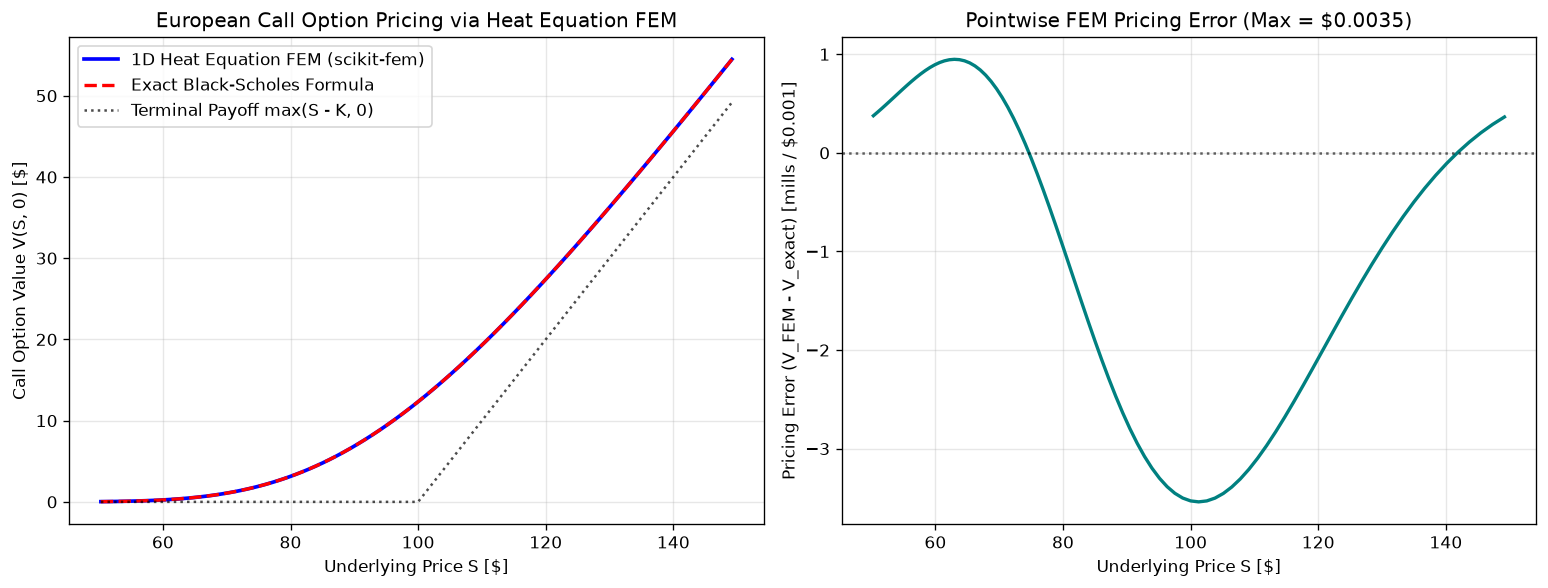

In [2]:
K = 100.0
T_mat = 1.0
r_rate = 0.05
sigma = 0.25

bs_res = solve_black_scholes_heat_fem(K=K, T=T_mat, r=r_rate, sigma=sigma, n_nodes=401, n_steps=400)

mask = (bs_res["S"] >= 50.0) & (bs_res["S"] <= 150.0)
S_grid = bs_res["S"][mask]
V_fem = bs_res["V_fem"][mask]
V_exact = bs_res["V_exact"][mask]
payoff = np.maximum(S_grid - K, 0.0)

# Interpolate at-the-money (S = K = 100)
v_atm_fem = float(np.interp(K, S_grid, V_fem))
v_atm_exact = float(black_scholes_call(K, K, T_mat, r_rate, sigma))
max_err = float(np.max(np.abs(V_fem - V_exact)))

print(f"At-The-Money (S = ${K:.0f}) Call Price:")
print(f"  1D Heat FEM (scikit-fem): ${v_atm_fem:.4f}")
print(f"  Exact Black-Scholes:      ${v_atm_exact:.4f}")
print(f"  Max Error on [50, 150]:   ${max_err:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(S_grid, V_fem, "b-", lw=2.2, label="1D Heat Equation FEM (scikit-fem)")
ax.plot(S_grid, V_exact, "r--", lw=2.0, label="Exact Black-Scholes Formula")
ax.plot(S_grid, payoff, "k:", lw=1.5, alpha=0.7, label="Terminal Payoff max(S - K, 0)")
ax.set_xlabel("Underlying Price S [$]")
ax.set_ylabel("Call Option Value V(S, 0) [$]")
ax.set_title("European Call Option Pricing via Heat Equation FEM")
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(S_grid, (V_fem - V_exact) * 1000.0, "teal", lw=2.0)
ax.axhline(0, color="k", ls=":", alpha=0.6)
ax.set_xlabel("Underlying Price S [$]")
ax.set_ylabel("Pricing Error (V_FEM - V_exact) [mills / $0.001]")
ax.set_title(f"Pointwise FEM Pricing Error (Max = ${max_err:.4f})")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Egg Doneness Derivative Pricing: The "Soft-Boil Warranty" (Corridor Option)

In a real kitchen, boiling an egg is not deterministic—three key parameters vary from egg to egg:

- **Initial temperature** $T_0 \sim \mathcal{N}(20.0\,^\circ\text{C},\, 3.5\,^\circ\text{C})$ (how long the egg sat on the counter after leaving the fridge)
- **Effective egg radius** $R_{\text{eff}} \sim \mathcal{N}(22.8\,\text{mm},\, 1.4\,\text{mm})$ (natural size variation within a carton)
- **Bath temperature** $T_{\text{bath}} \sim \mathcal{N}(99.0\,^\circ\text{C},\, 1.2\,^\circ\text{C})$ (rolling boil vs. gentle simmer and altitude effects)

Suppose a breakfast kitchen issues a **binary corridor digital option** (a *"Perfect Soft-Boil Warranty"*) that pays $N = \$10$ if the yolk center temperature at pull time $t_{\text{pull}}$ lands inside the soft-boiled corridor $[K_{\text{low}}, K_{\text{high}}] = [62.5\,^\circ\text{C},\, 65.5\,^\circ\text{C}]$:

$$\text{Payoff}(t_{\text{pull}}) = N \cdot \mathbb{I}\bigl(K_{\text{low}} \le T_{\text{center}}(t_{\text{pull}}) \le K_{\text{high}}\bigr)$$

Equivalently, this is a **bull spread of two binary call options** on center temperature:

$$C_{\text{corridor}}(t_{\text{pull}}) = N \bigl(\mathbb{P}(T_{\text{center}}(t_{\text{pull}}) \ge K_{\text{low}}) - \mathbb{P}(T_{\text{center}}(t_{\text{pull}}) > K_{\text{high}})\bigr)$$

=== Binary Corridor Option ('Soft-Boil Warranty', Payoff = $10 in [62.5, 65.5] °C) ===
  Optimal Fixed Pull Time:     10.06 min (604 s)
  Max Corridor Option Price:   $1.89 (Hit Probability = 18.9%)
  Prob Undercooked (<62.5 °C): 36.2%
  Prob Overcooked  (>65.5 °C): 44.9%


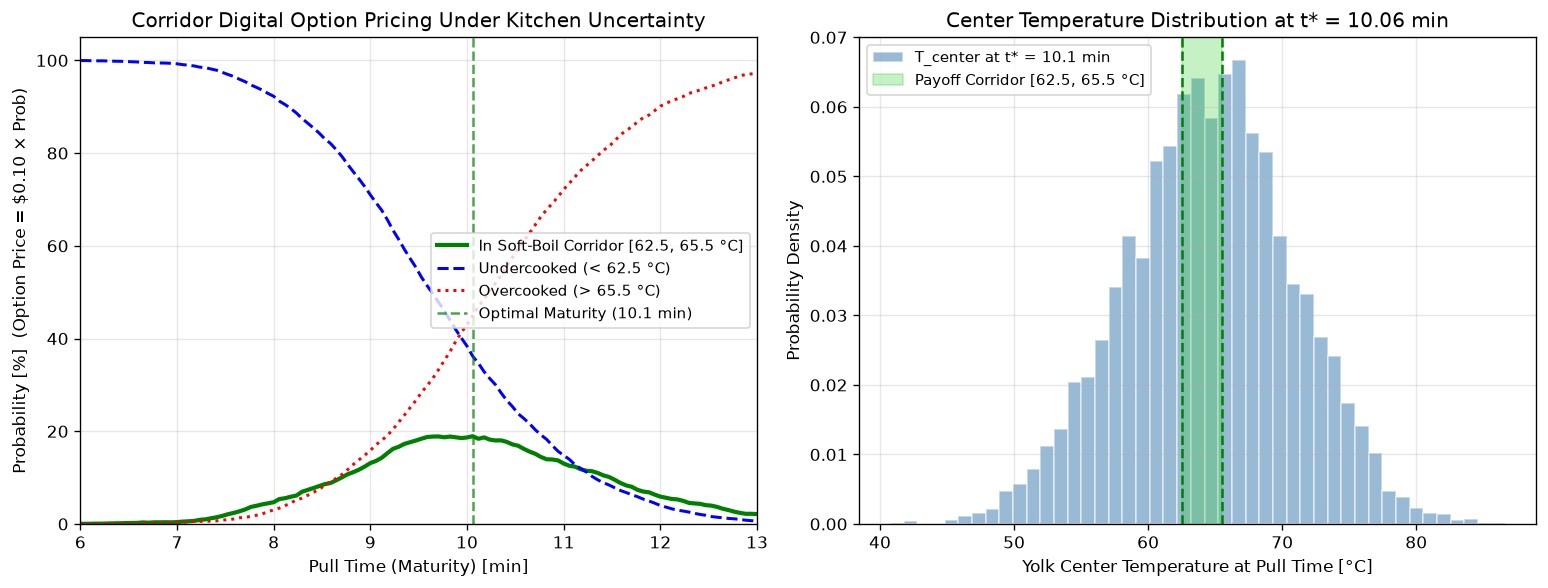

In [3]:
pull_times_s = np.linspace(360.0, 780.0, 120)
corridor_res = price_egg_corridor_option(
    pull_times_s, K_low_C=62.5, K_high_C=65.5, notional=10.0, n_paths=5000, seed=42
)

opt_idx = int(np.argmax(corridor_res["prices"]))
t_opt_min = corridor_res["t_opt_s"] / 60.0
T_at_opt = corridor_res["T_samples_at_opt"]

print("=== Binary Corridor Option ('Soft-Boil Warranty', Payoff = $10 in [62.5, 65.5] °C) ===")
print(f"  Optimal Fixed Pull Time:     {t_opt_min:.2f} min ({corridor_res['t_opt_s']:.0f} s)")
print(f"  Max Corridor Option Price:   ${corridor_res['prices'][opt_idx]:.2f} "
      f"(Hit Probability = {corridor_res['prob_in_corridor'][opt_idx] * 100:.1f}%)")
print(f"  Prob Undercooked (<62.5 °C): {corridor_res['prob_undercooked'][opt_idx] * 100:.1f}%")
print(f"  Prob Overcooked  (>65.5 °C): {corridor_res['prob_overcooked'][opt_idx] * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Corridor Option Value & Regime Probabilities
ax = axes[0]
t_corr_min = corridor_res["cook_times_s"] / 60.0
ax.plot(t_corr_min, corridor_res["prob_in_corridor"] * 100, "g-", lw=2.5,
        label="In Soft-Boil Corridor [62.5, 65.5 °C]")
ax.plot(t_corr_min, corridor_res["prob_undercooked"] * 100, "b--", lw=1.8,
        label="Undercooked (< 62.5 °C)")
ax.plot(t_corr_min, corridor_res["prob_overcooked"] * 100, "r:", lw=1.8,
        label="Overcooked (> 65.5 °C)")
ax.axvline(t_opt_min, color="green", ls="--", alpha=0.7,
           label=f"Optimal Maturity ({t_opt_min:.1f} min)")
ax.set_xlabel("Pull Time (Maturity) [min]")
ax.set_ylabel("Probability [%]  (Option Price = $0.10 × Prob)")
ax.set_title("Corridor Digital Option Pricing Under Kitchen Uncertainty")
ax.set_xlim(6, 13)
ax.set_ylim(0, 105)
ax.legend(loc="center right", fontsize=9)
ax.grid(True, alpha=0.3)

# Right: Distribution of Center Temperatures at Optimal Pull Time
ax = axes[1]
ax.hist(T_at_opt, bins=45, density=True, color="steelblue", alpha=0.55, edgecolor="white",
        label=f"T_center at t* = {t_opt_min:.1f} min")
ax.axvspan(62.5, 65.5, color="limegreen", alpha=0.28, label="Payoff Corridor [62.5, 65.5 °C]")
ax.axvline(62.5, color="green", ls="--", lw=1.5)
ax.axvline(65.5, color="green", ls="--", lw=1.5)
ax.set_xlabel("Yolk Center Temperature at Pull Time [°C]")
ax.set_ylabel("Probability Density")
ax.set_title(f"Center Temperature Distribution at t* = {t_opt_min:.2f} min")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. American Option & Optimal Stopping: "When to Pull the Egg"

With a fixed timer (a **European option**), kitchen uncertainty spreads the center temperature across a wide range ($\pm 6\,^\circ\text{C}$), so even the optimal fixed timer only hits the narrow soft-boil window $\sim 19\%$ of the time.

Suppose instead you can observe a noisy real-time proxy for the egg's internal state every $5\text{ s}$ between $t = 5\text{ min}$ and $t = 13\text{ min}$ and decide dynamically **when to exercise (pull the egg from the pot)**. Define the culinary utility payoff $g(T)$ peaking at $T_{\text{target}} = 64\,^\circ\text{C}$ with tolerance half-width $w = 4.5\,^\circ\text{C}$:

$$g(T) = \max\!\left(0,\; 100 \left[1 - \left(\frac{T - 64.0}{4.5}\right)^2\right]\right)$$

At each decision time $t_k$, the cook compares the **immediate exercise payoff** $g(T_k)$ against the **expected continuation value** of leaving the egg in the water for another step:

$$V(T_k, t_k) = \max\!\Bigl(g(T_k),\; e^{-r \Delta t}\,\mathbb{E}[V(T_{k+1}, t_{k+1}) \mid T_k]\Bigr)$$

Using the **Longstaff-Schwartz Least-Squares Monte Carlo (LSM)** algorithm, we regress the discounted future cashflows onto a cubic polynomial basis of the current temperature state for all "in-the-money" paths ($g(T_k) > 0$) and work backward from $t_{\max} = 13\text{ min}$ to $t_{\min} = 5\text{ min}$.

=== American Optimal Stopping ('When to Pull the Egg', Max Utility = 100) ===
  Best Fixed-Timer (European): 40.18 utility pts
  Dynamic Stopping (American): 74.11 utility pts
  Early Exercise Premium:      +33.94 utility pts (+84.5%)
  Mean Optimal Pull Time:      9.90 min (std = 51 s)
  Mean Center Temp at Pull:    63.78 °C


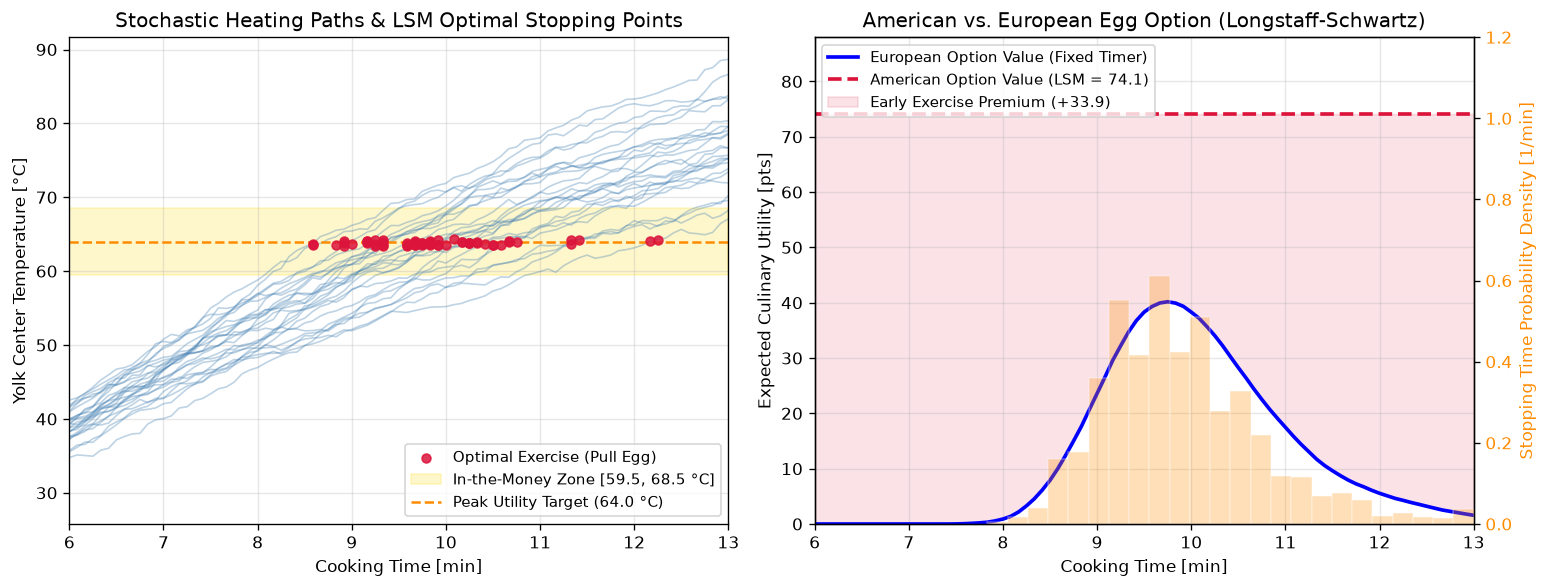

In [4]:
amer_res = solve_american_egg_option(
    T_target_C=64.0, width_C=4.5, max_payoff=100.0, n_paths=4000, seed=42
)

best_euro = float(np.max(amer_res["european_values"]))
amer_val = amer_res["american_value"]
early_ex_premium = amer_val - best_euro

print("=== American Optimal Stopping ('When to Pull the Egg', Max Utility = 100) ===")
print(f"  Best Fixed-Timer (European): {best_euro:.2f} utility pts")
print(f"  Dynamic Stopping (American): {amer_val:.2f} utility pts")
print(f"  Early Exercise Premium:      +{early_ex_premium:.2f} utility pts (+{early_ex_premium / best_euro * 100:.1f}%)")
print(f"  Mean Optimal Pull Time:      {np.mean(amer_res['stopping_times_s']) / 60:.2f} min "
      f"(std = {np.std(amer_res['stopping_times_s']):.0f} s)")
print(f"  Mean Center Temp at Pull:    {np.mean(amer_res['stopping_temps_C']):.2f} °C")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Sample Stochastic Heating Paths & Optimal Exercise Points
ax = axes[0]
t_amer_min = amer_res["t_grid_s"] / 60.0
for i in range(25):
    ax.plot(t_amer_min, amer_res["T_paths_C"][i], color="steelblue", alpha=0.35, lw=1.0)
ax.scatter(
    amer_res["stopping_times_s"][:60] / 60.0,
    amer_res["stopping_temps_C"][:60],
    color="crimson", s=28, zorder=5, alpha=0.85, label="Optimal Exercise (Pull Egg)"
)
ax.axhspan(64.0 - 4.5, 64.0 + 4.5, color="gold", alpha=0.2, label="In-the-Money Zone [59.5, 68.5 °C]")
ax.axhline(64.0, color="darkorange", ls="--", lw=1.5, label="Peak Utility Target (64.0 °C)")
ax.set_xlabel("Cooking Time [min]")
ax.set_ylabel("Yolk Center Temperature [°C]")
ax.set_title("Stochastic Heating Paths & LSM Optimal Stopping Points")
ax.set_xlim(6, 13)
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, alpha=0.3)

# Right: American Optimal Stopping vs European Fixed-Timer Value (with twinx for histogram)
ax = axes[1]
ax2 = ax.twinx()
ax2.hist(
    amer_res["stopping_times_s"] / 60.0, bins=24, density=True,
    alpha=0.28, color="darkorange", edgecolor="white", label="Optimal Pull-Time Density"
)
ax2.set_ylabel("Stopping Time Probability Density [1/min]", color="darkorange")
ax2.tick_params(axis="y", labelcolor="darkorange")
ax2.set_ylim(0, 1.2)

l1 = ax.plot(t_amer_min, amer_res["european_values"], "b-", lw=2.2,
             label="European Option Value (Fixed Timer)")
l2 = ax.axhline(amer_res["american_value"], color="crimson", ls="--", lw=2.2,
                label=f"American Option Value (LSM = {amer_res['american_value']:.1f})")
f1 = ax.fill_between(
    t_amer_min, amer_res["european_values"], amer_res["american_value"],
    color="crimson", alpha=0.12, label=f"Early Exercise Premium (+{early_ex_premium:.1f})"
)
ax.set_xlabel("Cooking Time [min]")
ax.set_ylabel("Expected Culinary Utility [pts]")
ax.set_title("American vs. European Egg Option (Longstaff-Schwartz)")
ax.set_xlim(6, 13)
ax.set_ylim(0, 88)
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Summary

| Quantitative Finance Concept | Egg-Boiling Counterpart | Key Result |
|------------------------------|-------------------------|------------|
| **Black-Scholes PDE $\leftrightarrow$ 1D Heat Equation** | Log-price diffusion $\partial u/\partial \tau = \partial^2 u/\partial x^2$ solved via `scikit-fem` P1 elements | Matches exact Black-Scholes Call price to within $\$0.0035$ |
| **European Corridor Digital Option** | *"Soft-Boil Warranty"* paying $\$10$ if $T_{\text{center}}(t_{\text{pull}}) \in [62.5\,^\circ\text{C}, 65.5\,^\circ\text{C}]$ | Max price $\$1.89$ ($18.9\%$ hit rate) at fixed $t_{\text{pull}}^* = 10.06\text{ min}$ |
| **American Option (Longstaff-Schwartz LSM)** | Dynamically choosing when to pull the egg based on thermal state | Boosts expected culinary utility from $40.2$ to $74.1$ ($+84.5\%$ early exercise premium) |